In [1]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [2]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")

In [3]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [4]:
#tokenizer
vocab_size = 1000
min_frequency = 2
corpus = [text for text in dataset["train"]["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [5]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [6]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [7]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [8]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [9]:
classifiers = OrderedDict()

In [10]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [11]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nl

In [12]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.297 seconds
Dataloader done! Time taken: 0.014 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\stanv\OneDrive\Documents\NLP1\Project1\smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\stanv\OneDrive\Documents\NLP1\Project1\smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.0379 | train acc: 0.5458 | val loss: 1.0102 | val acc: 0.4507
Epoch 02 | train loss: 0.8747 | train acc: 0.5739 | val loss: 0.9675 | val acc: 0.4507
Epoch 03 | train loss: 0.7640 | train acc: 0.5986 | val loss: 0.9452 | val acc: 0.4648
Epoch 04 | train loss: 0.6731 | train acc: 0.6831 | val loss: 0.9390 | val acc: 0.4789
Epoch 05 | train loss: 0.5958 | train acc: 0.7923 | val loss: 0.9355 | val acc: 0.4648
Epoch 06 | train loss: 0.5210 | train acc: 0.8908 | val loss: 0.9351 | val acc: 0.4789
Epoch 07 | train loss: 0.4543 | train acc: 0.9507 | val loss: 0.9348 | val acc: 0.5211
Epoch 08 | train loss: 0.3772 | train acc: 0.9613 | val loss: 0.9382 | val acc: 0.5634
Epoch 09 | train loss: 0.3235 | train acc: 0.9577 | val loss: 0.9463 | val acc: 0.5775
Epoch 10 | train loss: 0.2697 | train acc: 0.9648 | val loss: 0.9515 | val acc: 0.5775
Epoch 11 | train loss: 0.2197 | train acc: 0.9648 | val loss: 0.9560 | val acc: 0.5775
Epoch 12 | train loss: 0.1815 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0967 | train acc: 0.3627 | val loss: 1.0038 | val acc: 0.5775
Epoch 02 | train loss: 0.9471 | train acc: 0.6479 | val loss: 0.9162 | val acc: 0.5775
Epoch 03 | train loss: 0.8350 | train acc: 0.6761 | val loss: 0.8466 | val acc: 0.5915
Epoch 04 | train loss: 0.7462 | train acc: 0.6972 | val loss: 0.7940 | val acc: 0.6056
Epoch 05 | train loss: 0.6622 | train acc: 0.7746 | val loss: 0.7545 | val acc: 0.6479
Epoch 06 | train loss: 0.5939 | train acc: 0.8838 | val loss: 0.7217 | val acc: 0.7042
Epoch 07 | train loss: 0.5177 | train acc: 0.9331 | val loss: 0.6923 | val acc: 0.7606
Epoch 08 | train loss: 0.4527 | train acc: 0.9542 | val loss: 0.6655 | val acc: 0.7465
Epoch 09 | train loss: 0.3908 | train acc: 0.9577 | val loss: 0.6432 | val acc: 0.7465
Epoch 10 | train loss: 0.3303 | train acc: 0.9613 | val loss: 0.6276 | val acc: 0.7606
Epoch 11 | train loss: 0.2809 | train acc: 0.9613 | val loss: 0.6123 | val acc: 0.7465
Epoch 12 | train loss: 0.2390 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0656 | train acc: 0.4331 | val loss: 0.9771 | val acc: 0.4648
Epoch 02 | train loss: 0.9171 | train acc: 0.6937 | val loss: 0.8879 | val acc: 0.5352
Epoch 03 | train loss: 0.8191 | train acc: 0.7148 | val loss: 0.8175 | val acc: 0.5211
Epoch 04 | train loss: 0.7349 | train acc: 0.7007 | val loss: 0.7657 | val acc: 0.5352
Epoch 05 | train loss: 0.6643 | train acc: 0.7465 | val loss: 0.7299 | val acc: 0.5634
Epoch 06 | train loss: 0.5981 | train acc: 0.8239 | val loss: 0.6992 | val acc: 0.5775
Epoch 07 | train loss: 0.5341 | train acc: 0.8838 | val loss: 0.6763 | val acc: 0.5775
Epoch 08 | train loss: 0.4631 | train acc: 0.9366 | val loss: 0.6576 | val acc: 0.5775
Epoch 09 | train loss: 0.4002 | train acc: 0.9577 | val loss: 0.6433 | val acc: 0.6338
Epoch 10 | train loss: 0.3377 | train acc: 0.9577 | val loss: 0.6342 | val acc: 0.6620
Epoch 11 | train loss: 0.2863 | train acc: 0.9577 | val loss: 0.6317 | val acc: 0.6479
Epoch 12 | train loss: 0.2345 | train acc: 

In [13]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.215 seconds
Dataloader done! Time taken: 0.007 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0735 | train acc: 0.4718 | val loss: 1.0444 | val acc: 0.4366
Epoch 02 | train loss: 0.9589 | train acc: 0.5704 | val loss: 0.9851 | val acc: 0.4366
Epoch 03 | train loss: 0.8360 | train acc: 0.5634 | val loss: 0.9586 | val acc: 0.4366
Epoch 04 | train loss: 0.7226 | train acc: 0.5634 | val loss: 0.9722 | val acc: 0.4225
Epoch 05 | train loss: 0.6280 | train acc: 0.6690 | val loss: 0.9914 | val acc: 0.4507
Epoch 06 | train loss: 0.5330 | train acc: 0.8768 | val loss: 1.0007 | val acc: 0.5493
Epoch 07 | train loss: 0.4143 | train acc: 0.9366 | val loss: 1.0334 | val acc: 0.5070
Epoch 08 | train loss: 0.2999 | train acc: 0.9542 | val loss: 1.0478 | val acc: 0.5493
Epoch 09 | train loss: 0.1977 | train acc: 0.9718 | val loss: 1.0751 | val acc: 0.5352
Epoch 10 | train loss: 0.1338 | train acc: 0.9718 | val loss: 1.1387 | val acc: 0.5493
Epoch 11 | train loss: 0.0913 | train acc: 0.9754 | val loss: 1.2132 | val acc: 0.5634
Epoch 12 | train loss: 0.0667 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0580 | train acc: 0.4577 | val loss: 1.0093 | val acc: 0.2958
Epoch 02 | train loss: 0.9554 | train acc: 0.4577 | val loss: 0.9200 | val acc: 0.2958
Epoch 03 | train loss: 0.8613 | train acc: 0.5141 | val loss: 0.8227 | val acc: 0.3521
Epoch 04 | train loss: 0.7744 | train acc: 0.8134 | val loss: 0.7364 | val acc: 0.6901
Epoch 05 | train loss: 0.6940 | train acc: 0.8521 | val loss: 0.7034 | val acc: 0.7183
Epoch 06 | train loss: 0.5949 | train acc: 0.9014 | val loss: 0.6700 | val acc: 0.7042
Epoch 07 | train loss: 0.4805 | train acc: 0.9296 | val loss: 0.6585 | val acc: 0.6761
Epoch 08 | train loss: 0.3519 | train acc: 0.9437 | val loss: 0.6506 | val acc: 0.6338
Epoch 09 | train loss: 0.2404 | train acc: 0.9507 | val loss: 0.6196 | val acc: 0.7324
Epoch 10 | train loss: 0.1682 | train acc: 0.9542 | val loss: 0.6916 | val acc: 0.6479
Epoch 11 | train loss: 0.1136 | train acc: 0.9542 | val loss: 0.7962 | val acc: 0.6479
Epoch 12 | train loss: 0.0865 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0619 | train acc: 0.4437 | val loss: 0.9918 | val acc: 0.5775
Epoch 02 | train loss: 0.9530 | train acc: 0.6021 | val loss: 0.9022 | val acc: 0.5493
Epoch 03 | train loss: 0.8496 | train acc: 0.5599 | val loss: 0.8245 | val acc: 0.5493
Epoch 04 | train loss: 0.7581 | train acc: 0.6021 | val loss: 0.7825 | val acc: 0.5493
Epoch 05 | train loss: 0.6853 | train acc: 0.6585 | val loss: 0.7586 | val acc: 0.5915
Epoch 06 | train loss: 0.5864 | train acc: 0.8415 | val loss: 0.7237 | val acc: 0.7042
Epoch 07 | train loss: 0.4715 | train acc: 0.9225 | val loss: 0.6783 | val acc: 0.7183
Epoch 08 | train loss: 0.3588 | train acc: 0.9472 | val loss: 0.6535 | val acc: 0.7183
Epoch 09 | train loss: 0.2430 | train acc: 0.9542 | val loss: 0.6334 | val acc: 0.7465
Epoch 10 | train loss: 0.1705 | train acc: 0.9542 | val loss: 0.6237 | val acc: 0.7746
Epoch 11 | train loss: 0.1196 | train acc: 0.9577 | val loss: 0.6410 | val acc: 0.7746
Epoch 12 | train loss: 0.0880 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0893 | train acc: 0.3310 | val loss: 1.0082 | val acc: 0.5775
Epoch 02 | train loss: 0.9665 | train acc: 0.6866 | val loss: 0.8758 | val acc: 0.5211
Epoch 03 | train loss: 0.8489 | train acc: 0.5845 | val loss: 0.7646 | val acc: 0.5211
Epoch 04 | train loss: 0.7702 | train acc: 0.5528 | val loss: 0.7130 | val acc: 0.5211
Epoch 05 | train loss: 0.7043 | train acc: 0.5880 | val loss: 0.6868 | val acc: 0.5493
Epoch 06 | train loss: 0.6222 | train acc: 0.8099 | val loss: 0.6619 | val acc: 0.6338
Epoch 07 | train loss: 0.5168 | train acc: 0.9190 | val loss: 0.6420 | val acc: 0.6056
Epoch 08 | train loss: 0.4004 | train acc: 0.9437 | val loss: 0.6269 | val acc: 0.6620
Epoch 09 | train loss: 0.2837 | train acc: 0.9401 | val loss: 0.6220 | val acc: 0.6620
Epoch 10 | train loss: 0.1958 | train acc: 0.9613 | val loss: 0.6443 | val acc: 0.6761
Epoch 11 | train loss: 0.1364 | train acc: 0.9613 | val loss: 0.6856 | val acc: 0.6620
Epoch 12 | train loss: 0.0977 | train acc: 

In [14]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: '

In [15]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.167 seconds
Dataloader done! Time taken: 0.006 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0314 | train acc: 0.5317 | val loss: 0.9984 | val acc: 0.4930
Epoch 02 | train loss: 0.8674 | train acc: 0.6725 | val loss: 0.9531 | val acc: 0.4648
Epoch 03 | train loss: 0.7467 | train acc: 0.6937 | val loss: 0.9316 | val acc: 0.4648
Epoch 04 | train loss: 0.6532 | train acc: 0.7430 | val loss: 0.9216 | val acc: 0.5352
Epoch 05 | train loss: 0.5728 | train acc: 0.8451 | val loss: 0.9209 | val acc: 0.5352
Epoch 06 | train loss: 0.4958 | train acc: 0.9366 | val loss: 0.9145 | val acc: 0.5634
Epoch 07 | train loss: 0.4263 | train acc: 0.9472 | val loss: 0.9109 | val acc: 0.5775
Epoch 08 | train loss: 0.3628 | train acc: 0.9472 | val loss: 0.9123 | val acc: 0.5775
Epoch 09 | train loss: 0.3058 | train acc: 0.9613 | val loss: 0.9197 | val acc: 0.5775
Epoch 10 | train loss: 0.2495 | train acc: 0.9648 | val loss: 0.9254 | val acc: 0.6056
Epoch 11 | train loss: 0.2028 | train acc: 0.9754 | val loss: 0.9323 | val acc: 0.5915
Epoch 12 | train loss: 0.1661 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0909 | train acc: 0.3451 | val loss: 0.9943 | val acc: 0.5775
Epoch 02 | train loss: 0.9343 | train acc: 0.7289 | val loss: 0.8874 | val acc: 0.6056
Epoch 03 | train loss: 0.8234 | train acc: 0.7782 | val loss: 0.8073 | val acc: 0.6620
Epoch 04 | train loss: 0.7329 | train acc: 0.8345 | val loss: 0.7577 | val acc: 0.7465
Epoch 05 | train loss: 0.6569 | train acc: 0.8592 | val loss: 0.7227 | val acc: 0.7324
Epoch 06 | train loss: 0.5862 | train acc: 0.9155 | val loss: 0.6981 | val acc: 0.7324
Epoch 07 | train loss: 0.5175 | train acc: 0.9261 | val loss: 0.6766 | val acc: 0.7042
Epoch 08 | train loss: 0.4474 | train acc: 0.9437 | val loss: 0.6762 | val acc: 0.7042
Epoch 09 | train loss: 0.3857 | train acc: 0.9613 | val loss: 0.6627 | val acc: 0.6901
Epoch 10 | train loss: 0.3256 | train acc: 0.9613 | val loss: 0.6500 | val acc: 0.6901
Epoch 11 | train loss: 0.2700 | train acc: 0.9648 | val loss: 0.6374 | val acc: 0.6761
Epoch 12 | train loss: 0.2216 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0748 | train acc: 0.3979 | val loss: 1.0040 | val acc: 0.6056
Epoch 02 | train loss: 0.9358 | train acc: 0.7183 | val loss: 0.9204 | val acc: 0.5634
Epoch 03 | train loss: 0.8247 | train acc: 0.8239 | val loss: 0.8517 | val acc: 0.5634
Epoch 04 | train loss: 0.7294 | train acc: 0.8345 | val loss: 0.8020 | val acc: 0.5775
Epoch 05 | train loss: 0.6495 | train acc: 0.8662 | val loss: 0.7656 | val acc: 0.6197
Epoch 06 | train loss: 0.5653 | train acc: 0.9049 | val loss: 0.7366 | val acc: 0.6901
Epoch 07 | train loss: 0.4971 | train acc: 0.9085 | val loss: 0.7136 | val acc: 0.7183
Epoch 08 | train loss: 0.4291 | train acc: 0.9331 | val loss: 0.6914 | val acc: 0.7042
Epoch 09 | train loss: 0.3714 | train acc: 0.9577 | val loss: 0.6710 | val acc: 0.7606
Epoch 10 | train loss: 0.3108 | train acc: 0.9613 | val loss: 0.6533 | val acc: 0.7746
Epoch 11 | train loss: 0.2639 | train acc: 0.9648 | val loss: 0.6399 | val acc: 0.7746
Epoch 12 | train loss: 0.2192 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0529 | train acc: 0.4401 | val loss: 0.9639 | val acc: 0.5634
Epoch 02 | train loss: 0.9071 | train acc: 0.6972 | val loss: 0.8664 | val acc: 0.5634
Epoch 03 | train loss: 0.7893 | train acc: 0.7113 | val loss: 0.7964 | val acc: 0.5775
Epoch 04 | train loss: 0.7056 | train acc: 0.7289 | val loss: 0.7449 | val acc: 0.5775
Epoch 05 | train loss: 0.6300 | train acc: 0.7641 | val loss: 0.7043 | val acc: 0.5634
Epoch 06 | train loss: 0.5582 | train acc: 0.8556 | val loss: 0.6717 | val acc: 0.6620
Epoch 07 | train loss: 0.4878 | train acc: 0.9155 | val loss: 0.6479 | val acc: 0.6761
Epoch 08 | train loss: 0.4217 | train acc: 0.9401 | val loss: 0.6322 | val acc: 0.7042
Epoch 09 | train loss: 0.3594 | train acc: 0.9542 | val loss: 0.6197 | val acc: 0.7042
Epoch 10 | train loss: 0.3033 | train acc: 0.9542 | val loss: 0.6114 | val acc: 0.7042
Epoch 11 | train loss: 0.2584 | train acc: 0.9577 | val loss: 0.6063 | val acc: 0.6901
Epoch 12 | train loss: 0.2128 | train acc: 

In [16]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.225 seconds
Dataloader done! Time taken: 0.012 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0569 | train acc: 0.5423 | val loss: 1.0362 | val acc: 0.4366
Epoch 02 | train loss: 0.9254 | train acc: 0.5634 | val loss: 0.9726 | val acc: 0.4366
Epoch 03 | train loss: 0.7942 | train acc: 0.5634 | val loss: 0.9557 | val acc: 0.4366
Epoch 04 | train loss: 0.7045 | train acc: 0.5704 | val loss: 0.9825 | val acc: 0.4507
Epoch 05 | train loss: 0.6182 | train acc: 0.6725 | val loss: 1.0139 | val acc: 0.4648
Epoch 06 | train loss: 0.5171 | train acc: 0.8803 | val loss: 1.0143 | val acc: 0.4789
Epoch 07 | train loss: 0.3959 | train acc: 0.9507 | val loss: 1.0191 | val acc: 0.5493
Epoch 08 | train loss: 0.2788 | train acc: 0.9577 | val loss: 1.0487 | val acc: 0.5775
Epoch 09 | train loss: 0.1822 | train acc: 0.9718 | val loss: 1.0566 | val acc: 0.5634
Epoch 10 | train loss: 0.1244 | train acc: 0.9718 | val loss: 1.1077 | val acc: 0.5634
Epoch 11 | train loss: 0.0837 | train acc: 0.9754 | val loss: 1.2004 | val acc: 0.5634
Epoch 12 | train loss: 0.0623 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0702 | train acc: 0.4366 | val loss: 0.9786 | val acc: 0.6056
Epoch 02 | train loss: 0.9407 | train acc: 0.6162 | val loss: 0.8407 | val acc: 0.6901
Epoch 03 | train loss: 0.8213 | train acc: 0.5704 | val loss: 0.7494 | val acc: 0.7042
Epoch 04 | train loss: 0.7401 | train acc: 0.6408 | val loss: 0.7170 | val acc: 0.7042
Epoch 05 | train loss: 0.6661 | train acc: 0.8063 | val loss: 0.6989 | val acc: 0.6901
Epoch 06 | train loss: 0.5652 | train acc: 0.8944 | val loss: 0.6683 | val acc: 0.6901
Epoch 07 | train loss: 0.4496 | train acc: 0.9049 | val loss: 0.6383 | val acc: 0.7183
Epoch 08 | train loss: 0.3402 | train acc: 0.9190 | val loss: 0.6692 | val acc: 0.6620
Epoch 09 | train loss: 0.2373 | train acc: 0.9366 | val loss: 0.6495 | val acc: 0.7042
Epoch 10 | train loss: 0.1661 | train acc: 0.9472 | val loss: 0.6761 | val acc: 0.7042
Epoch 11 | train loss: 0.1174 | train acc: 0.9542 | val loss: 0.7726 | val acc: 0.6620
Epoch 12 | train loss: 0.0894 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0675 | train acc: 0.4401 | val loss: 0.9870 | val acc: 0.5493
Epoch 02 | train loss: 0.9334 | train acc: 0.5493 | val loss: 0.8788 | val acc: 0.5493
Epoch 03 | train loss: 0.8209 | train acc: 0.5387 | val loss: 0.8146 | val acc: 0.5493
Epoch 04 | train loss: 0.7527 | train acc: 0.5387 | val loss: 0.7992 | val acc: 0.5493
Epoch 05 | train loss: 0.6853 | train acc: 0.6690 | val loss: 0.7822 | val acc: 0.6479
Epoch 06 | train loss: 0.6023 | train acc: 0.8908 | val loss: 0.7599 | val acc: 0.6479
Epoch 07 | train loss: 0.5063 | train acc: 0.8732 | val loss: 0.7443 | val acc: 0.7042
Epoch 08 | train loss: 0.3819 | train acc: 0.9190 | val loss: 0.6966 | val acc: 0.7042
Epoch 09 | train loss: 0.2819 | train acc: 0.9366 | val loss: 0.6853 | val acc: 0.6901
Epoch 10 | train loss: 0.1984 | train acc: 0.9472 | val loss: 0.6962 | val acc: 0.6761
Epoch 11 | train loss: 0.1368 | train acc: 0.9613 | val loss: 0.6966 | val acc: 0.7183
Epoch 12 | train loss: 0.0992 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0386 | train acc: 0.5423 | val loss: 0.9724 | val acc: 0.5211
Epoch 02 | train loss: 0.9298 | train acc: 0.5458 | val loss: 0.8640 | val acc: 0.5211
Epoch 03 | train loss: 0.8264 | train acc: 0.5493 | val loss: 0.7714 | val acc: 0.5211
Epoch 04 | train loss: 0.7386 | train acc: 0.6021 | val loss: 0.7087 | val acc: 0.5634
Epoch 05 | train loss: 0.6643 | train acc: 0.7887 | val loss: 0.6623 | val acc: 0.5915
Epoch 06 | train loss: 0.5510 | train acc: 0.8627 | val loss: 0.6286 | val acc: 0.6620
Epoch 07 | train loss: 0.4307 | train acc: 0.8908 | val loss: 0.5992 | val acc: 0.6761
Epoch 08 | train loss: 0.3087 | train acc: 0.9261 | val loss: 0.5845 | val acc: 0.6901
Epoch 09 | train loss: 0.2107 | train acc: 0.9401 | val loss: 0.5930 | val acc: 0.6761
Epoch 10 | train loss: 0.1429 | train acc: 0.9472 | val loss: 0.6244 | val acc: 0.7042
Epoch 11 | train loss: 0.1019 | train acc: 0.9577 | val loss: 0.6587 | val acc: 0.7324
Epoch 12 | train loss: 0.0757 | train acc: 

In [17]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\stanv\envs\nlp1-2026\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: '

In [18]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.193 seconds
Dataloader done! Time taken: 0.005 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0961 | train acc: 0.4225 | val loss: 1.0865 | val acc: 0.4366
Epoch 02 | train loss: 1.0693 | train acc: 0.6127 | val loss: 1.0684 | val acc: 0.4225
Epoch 03 | train loss: 1.0400 | train acc: 0.6092 | val loss: 1.0475 | val acc: 0.4366
Epoch 04 | train loss: 1.0048 | train acc: 0.6373 | val loss: 1.0237 | val acc: 0.4366
Epoch 05 | train loss: 0.9642 | train acc: 0.6373 | val loss: 0.9988 | val acc: 0.4366
Epoch 06 | train loss: 0.9178 | train acc: 0.6373 | val loss: 0.9742 | val acc: 0.4366
Epoch 07 | train loss: 0.8707 | train acc: 0.6373 | val loss: 0.9521 | val acc: 0.4366
Epoch 08 | train loss: 0.8200 | train acc: 0.6373 | val loss: 0.9351 | val acc: 0.4366
Epoch 09 | train loss: 0.7756 | train acc: 0.6338 | val loss: 0.9228 | val acc: 0.4366
Epoch 10 | train loss: 0.7313 | train acc: 0.6373 | val loss: 0.9149 | val acc: 0.4366
Epoch 11 | train loss: 0.6898 | train acc: 0.6761 | val loss: 0.9105 | val acc: 0.4507
Epoch 12 | train loss: 0.6517 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0659 | train acc: 0.5000 | val loss: 1.0330 | val acc: 0.6901
Epoch 02 | train loss: 1.0406 | train acc: 0.5000 | val loss: 1.0108 | val acc: 0.6901
Epoch 03 | train loss: 1.0145 | train acc: 0.5035 | val loss: 0.9844 | val acc: 0.6901
Epoch 04 | train loss: 0.9850 | train acc: 0.5106 | val loss: 0.9532 | val acc: 0.6901
Epoch 05 | train loss: 0.9499 | train acc: 0.5493 | val loss: 0.9182 | val acc: 0.6901
Epoch 06 | train loss: 0.9104 | train acc: 0.5704 | val loss: 0.8825 | val acc: 0.7183
Epoch 07 | train loss: 0.8736 | train acc: 0.6514 | val loss: 0.8478 | val acc: 0.7324
Epoch 08 | train loss: 0.8316 | train acc: 0.7077 | val loss: 0.8146 | val acc: 0.7746
Epoch 09 | train loss: 0.7915 | train acc: 0.7746 | val loss: 0.7856 | val acc: 0.7324
Epoch 10 | train loss: 0.7513 | train acc: 0.8451 | val loss: 0.7625 | val acc: 0.7746
Epoch 11 | train loss: 0.7159 | train acc: 0.8908 | val loss: 0.7410 | val acc: 0.7606
Epoch 12 | train loss: 0.6774 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0863 | train acc: 0.4261 | val loss: 1.0693 | val acc: 0.4225
Epoch 02 | train loss: 1.0572 | train acc: 0.4331 | val loss: 1.0445 | val acc: 0.4507
Epoch 03 | train loss: 1.0277 | train acc: 0.5070 | val loss: 1.0145 | val acc: 0.5493
Epoch 04 | train loss: 0.9917 | train acc: 0.7077 | val loss: 0.9801 | val acc: 0.7183
Epoch 05 | train loss: 0.9499 | train acc: 0.8556 | val loss: 0.9435 | val acc: 0.7606
Epoch 06 | train loss: 0.9063 | train acc: 0.9366 | val loss: 0.9054 | val acc: 0.6479
Epoch 07 | train loss: 0.8631 | train acc: 0.8838 | val loss: 0.8694 | val acc: 0.5775
Epoch 08 | train loss: 0.8180 | train acc: 0.8310 | val loss: 0.8375 | val acc: 0.5634
Epoch 09 | train loss: 0.7787 | train acc: 0.7465 | val loss: 0.8097 | val acc: 0.5493
Epoch 10 | train loss: 0.7390 | train acc: 0.7254 | val loss: 0.7867 | val acc: 0.5493
Epoch 11 | train loss: 0.7041 | train acc: 0.7148 | val loss: 0.7675 | val acc: 0.5634
Epoch 12 | train loss: 0.6706 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1236 | train acc: 0.0458 | val loss: 1.1075 | val acc: 0.0563
Epoch 02 | train loss: 1.0948 | train acc: 0.4542 | val loss: 1.0815 | val acc: 0.6479
Epoch 03 | train loss: 1.0641 | train acc: 0.8345 | val loss: 1.0512 | val acc: 0.6338
Epoch 04 | train loss: 1.0292 | train acc: 0.8169 | val loss: 1.0159 | val acc: 0.5493
Epoch 05 | train loss: 0.9895 | train acc: 0.7254 | val loss: 0.9772 | val acc: 0.5493
Epoch 06 | train loss: 0.9473 | train acc: 0.6655 | val loss: 0.9367 | val acc: 0.5352
Epoch 07 | train loss: 0.9015 | train acc: 0.6373 | val loss: 0.8964 | val acc: 0.5352
Epoch 08 | train loss: 0.8553 | train acc: 0.6338 | val loss: 0.8586 | val acc: 0.5352
Epoch 09 | train loss: 0.8106 | train acc: 0.6056 | val loss: 0.8246 | val acc: 0.5352
Epoch 10 | train loss: 0.7665 | train acc: 0.6268 | val loss: 0.7953 | val acc: 0.5352
Epoch 11 | train loss: 0.7283 | train acc: 0.6690 | val loss: 0.7690 | val acc: 0.5634
Epoch 12 | train loss: 0.6908 | train acc: 

In [19]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.472 seconds
Dataloader done! Time taken: 0.014 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0741 | train acc: 0.4190 | val loss: 1.0253 | val acc: 0.5493
Epoch 02 | train loss: 0.9488 | train acc: 0.7183 | val loss: 0.9648 | val acc: 0.5915
Epoch 03 | train loss: 0.8250 | train acc: 0.6937 | val loss: 0.9310 | val acc: 0.4507
Epoch 04 | train loss: 0.7090 | train acc: 0.6268 | val loss: 0.9455 | val acc: 0.4507
Epoch 05 | train loss: 0.6248 | train acc: 0.6690 | val loss: 0.9646 | val acc: 0.5070
Epoch 06 | train loss: 0.5137 | train acc: 0.8979 | val loss: 0.9570 | val acc: 0.5775
Epoch 07 | train loss: 0.3939 | train acc: 0.9401 | val loss: 0.9713 | val acc: 0.5775
Epoch 08 | train loss: 0.2794 | train acc: 0.9472 | val loss: 0.9825 | val acc: 0.5493
Epoch 09 | train loss: 0.1809 | train acc: 0.9718 | val loss: 0.9942 | val acc: 0.5634
Epoch 10 | train loss: 0.1258 | train acc: 0.9718 | val loss: 1.0555 | val acc: 0.5634
Epoch 11 | train loss: 0.0827 | train acc: 0.9754 | val loss: 1.1348 | val acc: 0.5493
Epoch 12 | train loss: 0.0639 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1080 | train acc: 0.2500 | val loss: 1.0187 | val acc: 0.6620
Epoch 02 | train loss: 0.9884 | train acc: 0.6127 | val loss: 0.9077 | val acc: 0.6901
Epoch 03 | train loss: 0.8654 | train acc: 0.7430 | val loss: 0.8000 | val acc: 0.7465
Epoch 04 | train loss: 0.7559 | train acc: 0.8380 | val loss: 0.7330 | val acc: 0.7042
Epoch 05 | train loss: 0.6716 | train acc: 0.8592 | val loss: 0.7041 | val acc: 0.7606
Epoch 06 | train loss: 0.5753 | train acc: 0.8908 | val loss: 0.6782 | val acc: 0.7606
Epoch 07 | train loss: 0.4541 | train acc: 0.9120 | val loss: 0.6584 | val acc: 0.6620
Epoch 08 | train loss: 0.3360 | train acc: 0.9331 | val loss: 0.6657 | val acc: 0.6479
Epoch 09 | train loss: 0.2316 | train acc: 0.9437 | val loss: 0.6280 | val acc: 0.7606
Epoch 10 | train loss: 0.1630 | train acc: 0.9507 | val loss: 0.7195 | val acc: 0.6479
Epoch 11 | train loss: 0.1128 | train acc: 0.9542 | val loss: 0.8598 | val acc: 0.6197
Epoch 12 | train loss: 0.0892 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0749 | train acc: 0.3979 | val loss: 1.0238 | val acc: 0.4648
Epoch 02 | train loss: 0.9776 | train acc: 0.6514 | val loss: 0.9402 | val acc: 0.5775
Epoch 03 | train loss: 0.8728 | train acc: 0.7007 | val loss: 0.8572 | val acc: 0.5493
Epoch 04 | train loss: 0.7657 | train acc: 0.6972 | val loss: 0.8036 | val acc: 0.5634
Epoch 05 | train loss: 0.6731 | train acc: 0.7958 | val loss: 0.7790 | val acc: 0.5915
Epoch 06 | train loss: 0.5724 | train acc: 0.8768 | val loss: 0.7528 | val acc: 0.6761
Epoch 07 | train loss: 0.4536 | train acc: 0.9366 | val loss: 0.7177 | val acc: 0.6901
Epoch 08 | train loss: 0.3330 | train acc: 0.9437 | val loss: 0.6985 | val acc: 0.6761
Epoch 09 | train loss: 0.2324 | train acc: 0.9472 | val loss: 0.6864 | val acc: 0.7183
Epoch 10 | train loss: 0.1635 | train acc: 0.9542 | val loss: 0.6974 | val acc: 0.7324
Epoch 11 | train loss: 0.1121 | train acc: 0.9577 | val loss: 0.7063 | val acc: 0.7465
Epoch 12 | train loss: 0.0854 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0437 | train acc: 0.4683 | val loss: 0.9719 | val acc: 0.5352
Epoch 02 | train loss: 0.9367 | train acc: 0.6092 | val loss: 0.8653 | val acc: 0.5211
Epoch 03 | train loss: 0.8280 | train acc: 0.5915 | val loss: 0.7710 | val acc: 0.5352
Epoch 04 | train loss: 0.7303 | train acc: 0.6655 | val loss: 0.7085 | val acc: 0.5634
Epoch 05 | train loss: 0.6448 | train acc: 0.7923 | val loss: 0.6668 | val acc: 0.6056
Epoch 06 | train loss: 0.5387 | train acc: 0.8908 | val loss: 0.6317 | val acc: 0.6620
Epoch 07 | train loss: 0.4143 | train acc: 0.9155 | val loss: 0.6179 | val acc: 0.6338
Epoch 08 | train loss: 0.2973 | train acc: 0.9331 | val loss: 0.6151 | val acc: 0.6761
Epoch 09 | train loss: 0.2079 | train acc: 0.9437 | val loss: 0.6438 | val acc: 0.7042
Epoch 10 | train loss: 0.1443 | train acc: 0.9507 | val loss: 0.6907 | val acc: 0.6761
Epoch 11 | train loss: 0.1063 | train acc: 0.9577 | val loss: 0.7451 | val acc: 0.6901
Epoch 12 | train loss: 0.0784 | train acc: 

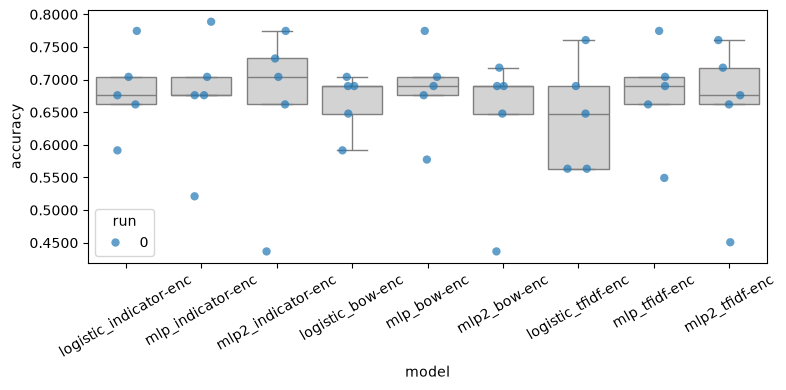

In [20]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [21]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.4798
P(Tie)    = 0.2418
P(B wins) = 0.2784
Effect Size = -0.29

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.5654
P(Tie)    = 0.1247
P(B wins) = 0.3099
Effect Size = -0.36

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.5154
P(Tie)    = 0.2200
P(B wins) = 0.2646
Effect Size = -0.36


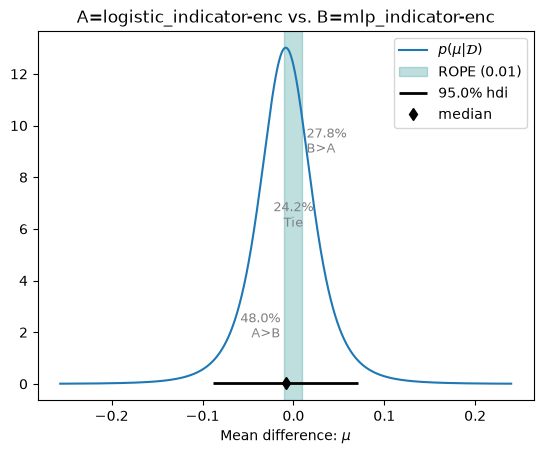

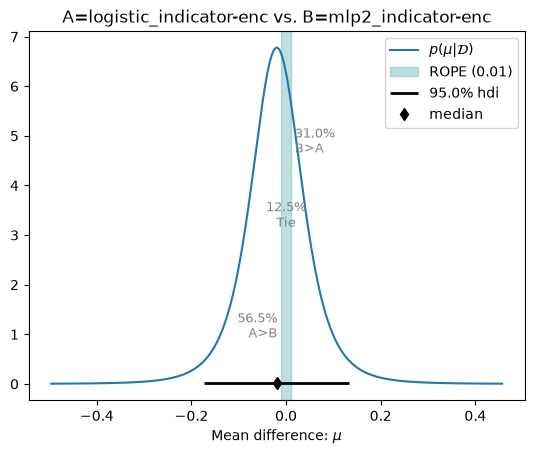

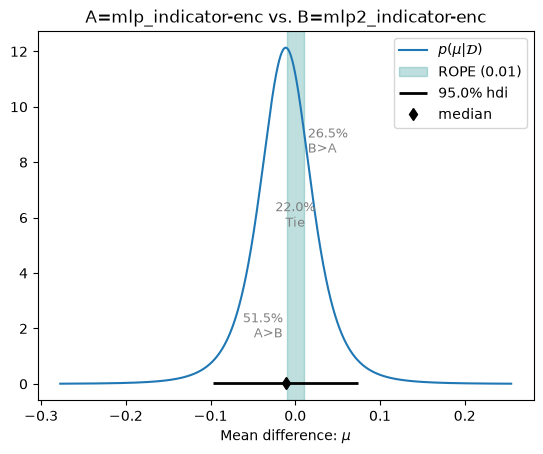

In [22]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.01

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [23]:
results = []

for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)
print(df.round(4))

                  Model A             Model B  P(A wins)  P(Tie)  P(B wins)  \
0  logistic_indicator-enc   mlp_indicator-enc     0.5448  0.1228     0.3325   
1  logistic_indicator-enc  mlp2_indicator-enc     0.5983  0.0626     0.3391   
2       mlp_indicator-enc  mlp2_indicator-enc     0.5754  0.1114     0.3132   

   Effect Size  
0      -0.2933  
1      -0.3563  
2      -0.3646  


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for sys_name, runs in classifiers.items():
    acc, prec, rec, f1 = [], [], [], []
    for r, run_data in enumerate(runs):
        for i, (fold, preds) in enumerate(run_data['predictions'].items()):
            gold = [y for _, y in my_cross_validation_sets[r][i]["validation"]]
            acc.append(accuracy_score(gold, preds))
            prec.append(precision_score(gold, preds, average="macro", zero_division=0))
            rec.append(recall_score(gold, preds, average="macro", zero_division=0))
            f1.append(f1_score(gold, preds, average="macro", zero_division=0))
    rows.append({
        "model": sys_name,
        "accuracy": np.mean(acc),
        "precision": np.mean(prec),
        "recall": np.mean(rec),
        "f1": np.mean(f1),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.round(4).to_string(index=False))

                 model  accuracy  precision  recall     f1
logistic_indicator-enc    0.6817     0.6328  0.5526 0.5601
     mlp_indicator-enc    0.6732     0.5635  0.5227 0.5171
    mlp2_indicator-enc    0.6620     0.4588  0.5025 0.4665
      logistic_bow-enc    0.6648     0.6232  0.5419 0.5492
           mlp_bow-enc    0.6845     0.5775  0.5327 0.5268
          mlp2_bow-enc    0.6366     0.4443  0.4822 0.4485
    logistic_tfidf-enc    0.6451     0.5281  0.4795 0.4485
         mlp_tfidf-enc    0.6761     0.5065  0.5118 0.4951
        mlp2_tfidf-enc    0.6535     0.5165  0.4927 0.4625
